# Mini-SOC — Étape 6 : module Machine Learning de classification des flux réseau

**Projet** : mini-SOC pour un réseau segmenté (VLAN + DMZ, principes Zero Trust) — pfSense, Suricata, Wazuh
**Cadre** : ENSA Kénitra, filière Réseaux et Systèmes de Télécommunications

**Objectif du notebook** : entraîner un modèle *léger et explicable* qui classe un flux réseau dans l'une des 5 classes
`Normal`, `PortScan`, `BruteForce`, `DoS`, `WebAttack` — les mêmes familles d'attaques que je rejouerai depuis Kali à l'étape 7 (nmap, hydra, DoS / HTTP flood).

**Plan**
1. Données : choix du dataset, chargement, regroupement des labels, nettoyage, déséquilibre des classes
2. Prétraitement : features, encodage, normalisation, séparation train/test stratifiée, rééquilibrage
3. Modèle : Random Forest + validation croisée
4. Évaluation : métriques par classe, matrices de confusion, importance des features, arbre explicatif
5. Sorties pour le rapport : PNG, modèle sauvegardé, tableau récapitulatif, fonction `predict(flux)`
6. Lien avec mon trafic réel (étape 7) : correspondance CICIDS2017 ↔ Zeek `conn.log`
7. Synthèse pour le rapport

> **Idée directrice** : j'entraîne **deux** Random Forest sur les mêmes flux.
> - **Modèle A « complet »** : toutes les features de CICIDS2017 → *référence* de performance.
> - **Modèle B « compatible Zeek »** : uniquement 13 features recalculables depuis un `conn.log` → c'est **celui que j'utiliserai à l'étape 7** sur mon propre trafic.
>
> Comparer les deux montre honnêtement ce que l'on perd en se limitant à ce que Zeek sait mesurer.

In [1]:
# --- IMPORTS ET CONFIGURATION ------------------------------------------------
# Uniquement des bibliothèques légères : pandas (tableaux), scikit-learn (ML),
# matplotlib/seaborn (graphiques), joblib (sauvegarde du modèle). Pas de deep learning.
import inspect
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Définitions partagées avec l'étape 7 (voir features_flux.py)
from features_flux import (CLASSES, FEATURES_CAT_ZEEK, FEATURES_NUM_ZEEK,
                           base_depuis_cicids, categoriser_service,
                           construire_features, regrouper_label)

warnings.filterwarnings("ignore", category=FutureWarning)

# Paramètres du notebook, regroupés ici pour être faciles à retrouver et à justifier
DOSSIER_DONNEES = Path("data/CICIDS2017")               # les 5 CSV du dossier MachineLearningCVE
FICHIER_ECHANTILLON = Path("data/echantillon_cicids2017.csv")   # secours si les CSV sont absents
FICHIERS = ["Monday-WorkingHours.pcap_ISCX.csv",                        # trafic normal uniquement
            "Tuesday-WorkingHours.pcap_ISCX.csv",                       # FTP-Patator, SSH-Patator
            "Wednesday-workingHours.pcap_ISCX.csv",                     # DoS (Hulk, GoldenEye, slowloris...)
            "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",   # attaques web
            "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv"]     # scan de ports
N_NORMAL_TRAIN = 250_000     # nombre de flux "Normal" conservés pour l'entraînement
TAILLE_TEST = 0.20           # 20 % des flux mis de côté pour l'évaluation finale
RANDOM_STATE = 42            # graine fixe -> résultats reproductibles devant le jury

DOSSIER_FIGURES = Path("sorties/figures"); DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)
DOSSIER_MODELES = Path("sorties/modeles"); DOSSIER_MODELES.mkdir(parents=True, exist_ok=True)

# Style graphique commun : fond blanc (insertion dans Word), une couleur FIXE par classe
COULEURS_CLASSES = {"Normal": "#2a78d6", "PortScan": "#eb6834", "BruteForce": "#1baf7a",
                    "DoS": "#eda100", "WebAttack": "#e87ba4"}
CMAP_BLEU = LinearSegmentedColormap.from_list("bleu", ["#ffffff", "#cde2fb", "#5598e7", "#0d366b"])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "grid.color": "#e1e0d9", "axes.titleweight": "bold", "axes.titlesize": 11})


def fmt(n):
    """Affiche un entier avec un séparateur de milliers lisible (1 234 567)."""
    return f"{int(n):,}".replace(",", " ")

## 1. Données

### 1.1 Choix du dataset : CICIDS2017 plutôt que NSL-KDD

| Critère | NSL-KDD | **CICIDS2017 (retenu)** |
|---|---|---|
| Époque du trafic | 1998-1999 (KDD Cup 99 nettoyé) | 2017 : HTTPS, SSH, attaques actuelles |
| Outils d'attaque | anciens (smurf, neptune, satan…) | **Patator, Hulk, GoldenEye, slowloris, nmap** → mêmes familles que mes scénarios Kali |
| Nature des features | certaines viennent du *contenu* des sessions (`num_failed_logins`, `root_shell`…) | **statistiques de flux** (durée, paquets, octets, débits) calculées par CICFlowMeter |
| Lien avec mon SOC | impossible à recalculer avec mes outils | **recalculables depuis Zeek `conn.log`** (section 6) |
| Taille | ~150 000 lignes | ~2,8 M de flux (j'en utilise 5 fichiers sur 8) |

NSL-KDD est plus petit et plus propre, mais ses attaques et ses features ne correspondent plus à ce que produit un réseau moderne.
CICIDS2017 contient exactement les attaques que je vais démontrer, et ses features sont de même nature que celles de Zeek : c'est ce qui rend l'étape 7 possible.

**Fichiers utilisés** (un par scénario) : Monday (normal), Tuesday (brute force FTP/SSH), Wednesday (DoS), Thursday-Morning (attaques web), Friday-Afternoon-PortScan.
Les 3 autres fichiers (Infiltration, Botnet, DDoS) ne correspondent à aucun de mes scénarios.

### 1.2 Où télécharger le dataset
1. Page officielle du Canadian Institute for Cybersecurity : <https://www.unb.ca/cic/datasets/ids-2017.html> (formulaire puis lien de téléchargement).
2. Télécharger **`MachineLearningCSV.zip`** (~225 Mo). Attention : le dossier à l'intérieur s'appelle `MachineLearningCVE`.
3. Copier les 5 fichiers listés ci-dessus dans `data/CICIDS2017/`.

Si les fichiers sont absents, le notebook bascule automatiquement sur `data/echantillon_cicids2017.csv` : un **extrait réel et brut** (~20 000 flux, toutes classes) produit par `creer_echantillon.py`. Il permet de tester tout le code, mais **les métriques du rapport doivent venir du dataset complet**.

In [2]:
# --- CHARGEMENT --------------------------------------------------------------
# Particularités des CSV de CICIDS2017, traitées ici explicitement :
#  * les noms de colonnes commencent par un espace (" Flow Duration") -> .str.strip()
#  * les labels "Web Attack" contiennent un tiret long mal encodé       -> encoding="latin-1" + nettoyage
#  * les types par défaut (int64/float64) doublent l'usage mémoire     -> on réduit en 32 bits
def reduire_memoire(df):
    """Convertit les colonnes numériques vers le plus petit type suffisant (RAM divisée par ~2)."""
    for col in df.select_dtypes("integer").columns:
        df[col] = pd.to_numeric(df[col], downcast="integer")
    for col in df.select_dtypes("float").columns:
        df[col] = pd.to_numeric(df[col], downcast="float")
    return df


def charger_fichier(chemin):
    df = pd.read_csv(chemin, encoding="latin-1", low_memory=False)
    df.columns = df.columns.str.strip()
    # Le tiret long de "Web Attack – XSS" est mal encodé : tout caractère hors ASCII imprimable
    # (l'intervalle [ -~] va de l'espace au tilde) est remplacé par un simple "-"
    df["Label"] = df["Label"].str.replace(r"[^ -~]+", "-", regex=True)
    return reduire_memoire(df)


chemins = [DOSSIER_DONNEES / f for f in FICHIERS]
DATASET_COMPLET = all(c.exists() for c in chemins)

if DATASET_COMPLET:
    morceaux = []
    for chemin in chemins:
        morceau = charger_fichier(chemin)
        print(f"{chemin.name:58s} {fmt(len(morceau)):>10s} flux")
        morceaux.append(morceau)
    brut = pd.concat(morceaux, ignore_index=True)
    del morceaux
else:
    print("!! Dataset complet introuvable -> utilisation de l'ÉCHANTILLON de test.")
    print("!! Les métriques obtenues ne sont PAS celles à mettre dans le rapport.")
    brut = charger_fichier(FICHIER_ECHANTILLON)

print(f"\nTotal : {fmt(len(brut))} flux, {brut.shape[1]} colonnes, "
      f"{brut.memory_usage(deep=True).sum() / 1e6:.0f} Mo en mémoire")
print("\nLabels d'origine :")
print(brut["Label"].value_counts().to_string())

Monday-WorkingHours.pcap_ISCX.csv                             529 918 flux


Tuesday-WorkingHours.pcap_ISCX.csv                            445 909 flux


Wednesday-workingHours.pcap_ISCX.csv                          692 703 flux


Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv        170 366 flux


Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv          286 467 flux



Total : 2 125 363 flux, 79 colonnes, 796 Mo en mémoire

Labels d'origine :
Label
BENIGN                        1697746
DoS Hulk                       231073
PortScan                       158930
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Web Attack - Brute Force         1507
Web Attack - XSS                  652
Web Attack - Sql Injection         21
Heartbleed                         11


### 1.3 Regroupement des labels en 5 classes

| Label(s) CICIDS2017 | Classe du projet | Scénario Kali correspondant (étape 7) | Justification |
|---|---|---|---|
| `BENIGN` | **Normal** | trafic des postes des VLAN | — |
| `PortScan` | **PortScan** | `nmap` | reconnaissance : beaucoup de flux très courts, presque vides |
| `FTP-Patator`, `SSH-Patator` | **BruteForce** | `hydra` sur SSH | même mécanisme : essais répétés de mots de passe sur un service d'authentification |
| `DoS Hulk`, `DoS GoldenEye`, `DoS slowloris`, `DoS Slowhttptest` | **DoS** | DoS + **HTTP Flood** | Hulk et GoldenEye *sont* des HTTP floods ; slowloris/Slowhttptest sont des DoS « lents » (épuisement des connexions) : même objectif, l'indisponibilité du service |
| `Web Attack – Brute Force`, `– XSS`, `– Sql Injection` | **WebAttack** | trafic web malveillant | attaques *applicatives* portées par HTTP. Le brute force de formulaire web est rangé ici (et non dans BruteForce) car, vu du réseau, c'est du trafic HTTP : c'est ce que verra Suricata |
| `Heartbleed` (11 flux) | *exclu* | aucun | exploitation d'une faille OpenSSL : hors de mes scénarios, et 11 exemples ne permettent pas d'apprendre une classe |

**Cas de l'ARP spoofing / mouvement latéral** : l'ARP spoofing est une attaque de **couche 2** ; elle ne crée pas de « flux » IP et n'existe ni dans CICIDS2017 ni dans `conn.log`. Elle reste donc du ressort de Suricata/Wazuh (et d'outils comme arpwatch), pas du module ML. En revanche, un mouvement latéral entre VLAN se manifeste concrètement par des scans et des tentatives de connexion *internes* : ces flux-là sont bien couverts par les classes `PortScan` et `BruteForce`.

In [3]:
# --- REGROUPEMENT DES LABELS -------------------------------------------------
# La fonction vit dans features_flux.py (réutilisée à l'étape 7) ; on affiche son
# code ici pour que la règle de regroupement soit visible dans le notebook.
print(inspect.getsource(regrouper_label))

brut["classe"] = brut["Label"].map(regrouper_label)

# Tableau de contrôle : chaque label d'origine est-il bien rangé dans la bonne classe ?
controle = (brut.assign(classe=brut["classe"].fillna("(exclu)"))
                .groupby(["classe", "Label"]).size().rename("nb_flux").reset_index())
display(controle)

def regrouper_label(label):
    """Convertit un label d'origine CICIDS2017 en l'une des 5 classes du projet.

    Les labels "Web Attack" contiennent un caractère mal encodé dans les CSV
    (tiret long) : on les reconnaît donc par leur préfixe plutôt que par égalité.
    """
    label = str(label).strip()
    if label.startswith("Web Attack"):
        return "WebAttack"
    return MAPPING_LABELS.get(label)



,classe,Label,nb_flux
0,(exclu),Heartbleed,11
1,BruteForce,FTP-Patator,7938
2,BruteForce,SSH-Patator,5897
3,DoS,DoS GoldenEye,10293
4,DoS,DoS Hulk,231073
5,DoS,DoS Slowhttptest,5499
6,DoS,DoS slowloris,5796
7,Normal,BENIGN,1697746
8,PortScan,PortScan,158930
9,WebAttack,Web Attack - Brute Force,1507


### 1.4 Nettoyage explicite

CICIDS2017 est connu pour ses défauts ; chacun est traité par une étape visible et comptée :

| Problème | Cause | Traitement | Pourquoi |
|---|---|---|---|
| Colonne `Fwd Header Length` en double | bug d'export de CICFlowMeter | suppression du doublon | information redondante |
| Valeurs `Infinity` et `NaN` (`Flow Bytes/s`, `Flow Packets/s`) | division par une durée de flux nulle | `Infinity` → `NaN`, puis **suppression** des lignes | ~0,1 % des flux : les supprimer ne change pas la distribution, alors qu'imputer reviendrait à *inventer* un débit |
| Durées négatives | artefact de CICFlowMeter | suppression des lignes | valeur physiquement impossible |
| Lignes strictement identiques | flux répétitifs (scans, floods) exportés à l'identique | `drop_duplicates()` **avant** la séparation train/test | sinon le même flux se retrouve dans train *et* test → score artificiellement gonflé (fuite de données) |
| Colonnes constantes (toujours 0) | compteurs jamais alimentés | suppression | une colonne constante n'apporte aucune information |

In [4]:
# --- NETTOYAGE, ÉTAPE PAR ÉTAPE, AVEC COMPTAGE --------------------------------
# On garde une trace du nombre de lignes après chaque étape : ce tableau va dans le rapport.
journal = [("Flux chargés", len(brut))]

# (1) Colonne dupliquée : pandas l'a renommée "Fwd Header Length.1" à la lecture
df = brut.drop(columns=["Fwd Header Length.1"], errors="ignore")
del brut

# (2) Flux hors périmètre (Heartbleed -> classe None)
df = df[df["classe"].notna()].drop(columns="Label")
journal.append(("Après exclusion de Heartbleed", len(df)))

# (3) Infinity -> NaN, puis suppression des lignes incomplètes
colonnes_num = df.select_dtypes("number").columns
nb_inf = int(np.isinf(df[colonnes_num]).sum().sum())
nb_nan = int(df[colonnes_num].isna().sum().sum())
print(f"Valeurs Infinity : {fmt(nb_inf)}   |   valeurs NaN : {fmt(nb_nan)}")
print("Colonnes concernées :", [c for c in colonnes_num
                                if np.isinf(df[c]).any() or df[c].isna().any()])
df = df.replace([np.inf, -np.inf], np.nan).dropna()
journal.append(("Après suppression des NaN / Infinity", len(df)))

# (4) Durées négatives (impossibles physiquement)
df = df[df["Flow Duration"] >= 0]
journal.append(("Après suppression des durées négatives", len(df)))

# (5) Doublons exacts — AVANT le split pour éviter toute fuite train -> test
df = df.drop_duplicates().reset_index(drop=True)
journal.append(("Après suppression des doublons", len(df)))

# (6) Colonnes constantes
constantes = [c for c in df.columns if df[c].nunique() <= 1]
df = df.drop(columns=constantes)
print(f"Colonnes constantes supprimées ({len(constantes)}) : {constantes}")

journal = pd.DataFrame(journal, columns=["Étape", "Flux restants"])
journal["Flux retirés"] = -journal["Flux restants"].diff().fillna(0).astype(int)
display(journal)
print(f"Jeu nettoyé : {fmt(len(df))} flux, {df.shape[1] - 1} features + la classe")

Valeurs Infinity : 3 700   |   valeurs NaN : 1 308


Colonnes concernées : ['Flow Bytes/s', 'Flow Packets/s']


Colonnes constantes supprimées (10) : ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


,Étape,Flux restants,Flux retirés
0,Flux chargés,2125363,0
1,Après exclusion de Heartbleed,2125352,11
2,Après suppression des NaN / Infinity,2122848,2504
3,Après suppression des durées négatives,2122748,100
4,Après suppression des doublons,1889004,233744


Jeu nettoyé : 1 889 004 flux, 67 features + la classe


### 1.5 Déséquilibre des classes

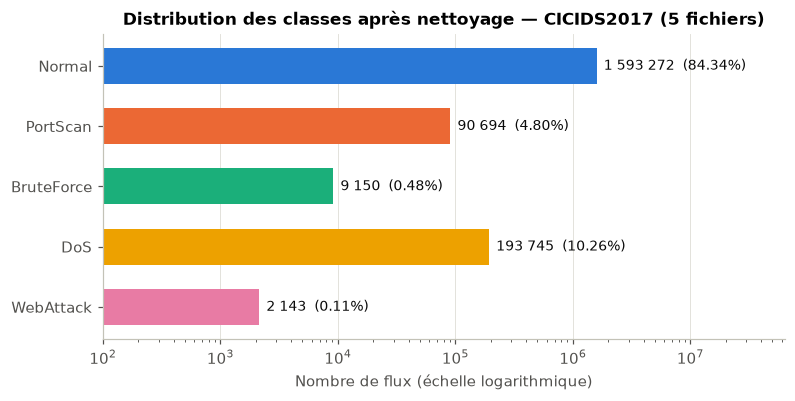

Il y a 743 flux Normal pour 1 flux WebAttack.


In [5]:
# --- DISTRIBUTION DES CLASSES (FIGURE 1) --------------------------------------
# Échelle LOGARITHMIQUE : en échelle linéaire, WebAttack (~0,1 %) serait invisible.
# Les effectifs exacts sont écrits à côté des barres pour qu'on ne lise pas mal l'échelle log.
distribution = df["classe"].value_counts().reindex(CLASSES)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(distribution.index, distribution.values, height=0.6,
        color=[COULEURS_CLASSES[c] for c in distribution.index])
ax.set_xscale("log")
ax.set_xlim(100, distribution.max() * 40)
ax.invert_yaxis()
for i, (classe, n) in enumerate(distribution.items()):
    ax.text(n * 1.15, i, f"{fmt(n)}  ({n / distribution.sum():.2%})", va="center",
            fontsize=9, color="#0b0b0b")
ax.set_xlabel("Nombre de flux (échelle logarithmique)")
ax.set_title("Distribution des classes après nettoyage — CICIDS2017 (5 fichiers)")
ax.grid(axis="x", linewidth=0.6); ax.set_axisbelow(True)
fig.savefig(DOSSIER_FIGURES / "01_distribution_classes.png")
plt.show()

ratio = distribution["Normal"] / distribution["WebAttack"]
print(f"Il y a {ratio:.0f} flux Normal pour 1 flux WebAttack.")

**Pourquoi c'est un problème.** Un modèle qui répondrait toujours « Normal » aurait déjà ~84 % d'accuracy… en ne détectant *aucune* attaque. Deux conséquences :
- l'**accuracy seule est trompeuse** → je rapporte surtout le rappel, la précision et le **F1 macro** (moyenne simple des 5 classes, où WebAttack compte autant que Normal) ;
- il faut **rééquilibrer l'apprentissage**. Stratégie retenue, en deux temps (appliquée en section 2) :

1. **Sous-échantillonnage de la classe `Normal`, uniquement dans le jeu d'entraînement** (250 000 flux gardés). C'est la classe énorme : en retirer ne fait perdre presque aucune information, réduit la RAM et le temps de calcul. Les classes d'attaque, elles, sont **toutes conservées** (chaque exemple est précieux).
2. **`class_weight="balanced"`** dans le Random Forest pour le déséquilibre restant : une erreur sur un flux WebAttack « coûte » plus cher qu'une erreur sur un flux Normal, proportionnellement à la rareté de la classe.

*Pourquoi pas SMOTE (sur-échantillonnage synthétique) ?* Il fabriquerait des flux artificiels par interpolation — difficile à justifier physiquement pour du trafic réseau — et demande une bibliothèque supplémentaire. La pondération obtient le même effet sans inventer de données.

**Point de méthode important** : le **jeu de test n'est pas rééquilibré**. Il garde la proportion réelle (Normal ultra-majoritaire), car c'est la situation que le modèle rencontrera dans le SOC. Rééquilibrer le test embellirait artificiellement la précision.

## 2. Prétraitement

### 2.1 Les deux jeux de features

**Modèle A « complet »** : toutes les colonnes numériques nettoyées de CICFlowMeter (durées, tailles de paquets, inter-arrivées, flags, fenêtres TCP…) + la variable catégorielle `service`.

**Modèle B « compatible Zeek »** : 13 features **recalculées** à partir de 6 grandeurs de base que Zeek fournit aussi (durée, paquets et octets dans chaque sens, port de destination). Le calcul est fait par `construire_features()` — la **même fonction** servira à l'étape 7, ce qui garantit des définitions identiques.

**Variable catégorielle `service`** : le port de destination est un *identifiant*, pas une grandeur (443 n'est pas « plus grand » que 80). Je le remplace par une catégorie : `ssh`, `ftp`, `http`, `https`, `dns`, `autre_systeme` (< 1024), `autre_haut`. Avantage : un scan nmap touche des milliers de ports → ils tombent tous dans `autre_*`, le modèle apprend un *comportement* plutôt que des numéros de port.

**Correction d'un artefact de CICIDS2017 : le bourrage Ethernet.** Une trame Ethernet fait au minimum 60 octets ; un paquet TCP *sans données* (SYN, RST, ACK pur : 54 à 58 octets) est donc complété par 2 à 6 octets de bourrage. CICFlowMeter compte ce bourrage comme de la charge utile, **Zeek non**. Conséquence vérifiée dans les données : 99 % des flux PortScan valent « 0 ou 2 octets aller, 6 octets retour ». Un modèle entraîné tel quel apprend la règle *« 6 octets retour = scan »* : excellente sur le papier (≈ 99,9 %)… et **fausse sur mon réseau**, où Zeek écrira 0 octet (je l'ai constaté : sans correction, les sondes nmap du `conn.log` d'exemple étaient classées `Normal`). `construire_features()` met donc à 0 les octets d'un sens qui transporte au plus 6 octets par paquet. Le modèle B est ainsi **volontairement privé d'un raccourci** propre au dataset : ses scores sont plus bas, mais ils veulent dire quelque chose pour l'étape 7.

Le **modèle A**, lui, utilise le dataset *tel que publié* (comme la plupart des articles) : il sert de référence, en sachant qu'une partie de son score quasi parfait vient de ce type d'artefacts (bourrage, `Init_Win_bytes` propres aux machines du banc d'essai).

**Features volontairement écartées du modèle B** : les compteurs de flags TCP. L'exploration montre que `RST Flag Count` vaut **toujours 0** dans CICIDS2017 et que `SYN Flag Count` vaut 0 pour les PortScan — ce qui est impossible (bug connu de CICFlowMeter). S'appuyer dessus donnerait un modèle inutilisable sur du vrai trafic.

In [6]:
# --- CONSTRUCTION DES FEATURES -------------------------------------------------
# On affiche le code de construire_features() : c'est LA définition des 13 features du modèle B.
print(inspect.getsource(construire_features))

y = df["classe"]

# Modèle B : 6 grandeurs de base -> 13 features (12 numériques + service)
X_zeek = construire_features(base_depuis_cicids(df))

# Modèle A : toutes les colonnes numériques SAUF le port brut (remplacé par "service")
COLS_NUM_COMPLET = [c for c in df.columns if c not in ("classe", "Destination Port")]
X_complet = df[COLS_NUM_COMPLET].copy()
X_complet["service"] = X_zeek["service"]

print(f"Modèle A (complet)        : {len(COLS_NUM_COMPLET)} features numériques + 'service'")
print(f"Modèle B (compatible Zeek): {len(FEATURES_NUM_ZEEK)} features numériques + 'service'")
display(X_zeek.assign(classe=y).groupby("classe").median(numeric_only=True).round(3).T)

def construire_features(base):
    """À partir des 6 grandeurs de base, calcule les 13 features du modèle.

    La même fonction est appelée sur CICIDS2017 (entraînement) et sur Zeek
    (étape 7) : les définitions sont donc garanties identiques.
    """
    f = pd.DataFrame(index=base.index)
    f["duree_s"] = base["duree_s"].clip(lower=0)
    f["paquets_aller"] = base["paquets_aller"]
    f["paquets_retour"] = base["paquets_retour"]
    # Neutralisation du BOURRAGE ETHERNET (voir _sans_bourrage ci-dessus)
    f["octets_aller"] = _sans_bourrage(base["octets_aller"], base["paquets_aller"])
    f["octets_retour"] = _sans_bourrage(base["octets_retour"], base["paquets_retour"])
    # Volumes totaux du flux
    f["paquets_total"] = f["paquets_aller"] + f["paquets_retour"]
    f["octets_total"] = f["octets_aller"] + f["octets_retour"]
    # Débits : un DoS/flood se voit au débit, un scan à sa brièveté
    f["octets_par_s"] = _division_sure(f["octets_total"], f["duree_s"])
    f["paquets_par

Modèle A (complet)        : 66 features numériques + 'service'
Modèle B (compatible Zeek): 12 features numériques + 'service'


classe,BruteForce,DoS,Normal,PortScan,WebAttack
duree_s,9.114,85.872,0.038,0.0,5.487
paquets_aller,9.000,6.000,2.000,1.0,3.000
paquets_retour,15.000,6.000,2.000,1.0,1.000
octets_aller,107.000,354.000,69.000,0.0,0.000
octets_retour,188.000,11595.000,153.000,0.0,0.000
paquets_total,24.000,13.000,4.000,2.0,4.000
octets_total,295.000,11946.000,236.000,0.0,0.000
octets_par_s,353.910,121.798,2516.424,0.0,0.000
paquets_par_s,4.064,0.150,85.183,40000.0,0.741
taille_moy_aller,11.889,53.500,38.000,0.0,0.000


Le tableau ci-dessus (médianes par classe) montre déjà des **signatures lisibles** : un PortScan dure quelques dizaines de microsecondes avec 1-2 paquets quasi vides ; un DoS dure des dizaines de secondes ; un BruteForce se situe entre les deux avec de petits paquets.

### 2.2 Séparation train / test stratifiée, puis rééquilibrage du train

- **80 % / 20 %**, avec `stratify=y` : chaque classe garde la même proportion dans les deux jeux. Indispensable ici : sans stratification, le hasard pourrait laisser très peu de WebAttack dans le test.
- Le split est fait **une seule fois** (sur les index) : les modèles A et B sont entraînés et testés sur **exactement les mêmes flux** → comparaison équitable.
- Le test est mis de côté et **n'est plus touché** avant l'évaluation finale.

Train avant rééquilibrage : 1 511 203 flux
Train après rééquilibrage : 486 585 flux
Test (distribution réelle): 377 801 flux


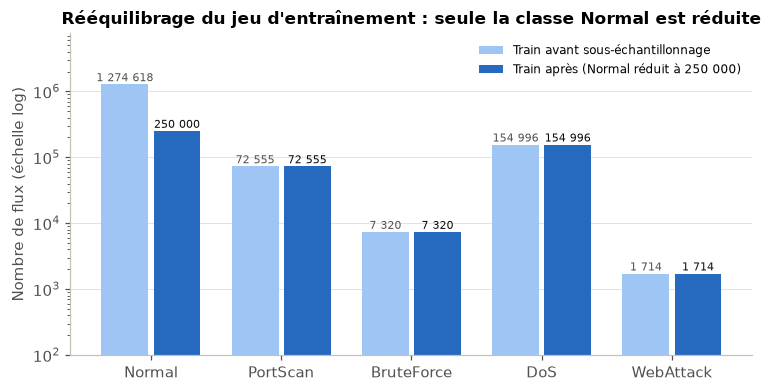

In [7]:
# --- SPLIT STRATIFIÉ PUIS SOUS-ÉCHANTILLONNAGE DE "Normal" (TRAIN UNIQUEMENT) ---
idx_train, idx_test = train_test_split(df.index, test_size=TAILLE_TEST,
                                       stratify=y, random_state=RANDOM_STATE)
y_test = y.loc[idx_test]

# Sous-échantillonnage : on tire N_NORMAL_TRAIN flux Normal au hasard dans le TRAIN ;
# toutes les attaques sont conservées. Le TEST n'est pas modifié (distribution réelle).
y_train_brut = y.loc[idx_train]
idx_normal = y_train_brut[y_train_brut == "Normal"].index
idx_attaques = y_train_brut[y_train_brut != "Normal"].index
n_normal = min(N_NORMAL_TRAIN, len(idx_normal))
idx_normal_garde = pd.Index(np.random.RandomState(RANDOM_STATE)
                            .choice(idx_normal, size=n_normal, replace=False))
idx_train_eq = idx_normal_garde.union(idx_attaques)
y_train = y.loc[idx_train_eq]

print(f"Train avant rééquilibrage : {fmt(len(idx_train))} flux")
print(f"Train après rééquilibrage : {fmt(len(idx_train_eq))} flux")
print(f"Test (distribution réelle): {fmt(len(idx_test))} flux")

# FIGURE 2 : effet du rééquilibrage sur le jeu d'entraînement
avant = y_train_brut.value_counts().reindex(CLASSES)
apres = y_train.value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(8, 3.8))
pos = np.arange(len(CLASSES))
ax.bar(pos - 0.2, avant.values, width=0.36, color="#9ec5f4", label="Train avant sous-échantillonnage")
ax.bar(pos + 0.2, apres.values, width=0.36, color="#256abf", label="Train après (Normal réduit à 250 000)")
for x, n in zip(pos - 0.2, avant.values):
    ax.text(x, n * 1.12, fmt(n), ha="center", fontsize=7.5, color="#52514e")
for x, n in zip(pos + 0.2, apres.values):
    ax.text(x, n * 1.12, fmt(n), ha="center", fontsize=7.5, color="#0b0b0b")
ax.set_yscale("log"); ax.set_ylim(100, avant.max() * 6)
ax.set_xticks(pos); ax.set_xticklabels(CLASSES)
ax.set_ylabel("Nombre de flux (échelle log)")
ax.set_title("Rééquilibrage du jeu d'entraînement : seule la classe Normal est réduite")
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.grid(axis="y", linewidth=0.6); ax.set_axisbelow(True)
fig.savefig(DOSSIER_FIGURES / "02_reequilibrage_train.png")
plt.show()

### 2.3 Encodage et normalisation, dans un `Pipeline`

- **Encodage one-hot** de `service` : une colonne 0/1 par catégorie. Pas d'encodage ordinal (ssh=1, ftp=2…) car il créerait un ordre artificiel entre services. `handle_unknown="ignore"` : une catégorie inconnue donnerait des zéros au lieu d'une erreur.
- **Normalisation `StandardScaler`** des variables numériques (moyenne 0, écart-type 1). **Transparence pour le jury** : un arbre de décision compare chaque feature à un seuil, il est donc *insensible* à l'échelle — la normalisation **ne change pas** les résultats du Random Forest. Je la garde car (1) c'est une bonne pratique qui permet de remplacer le modèle par un autre (régression logistique, k-NN, SVM) sans rien changer d'autre, et (2) elle est demandée dans la chaîne de prétraitement classique.
- **Pourquoi un `Pipeline` ?** Le scaler et l'encodeur sont *appris sur le train uniquement*, puis appliqués tels quels au test → **aucune fuite d'information** du test vers l'entraînement. Et le fichier sauvegardé contient prétraitement + modèle : `predict()` reçoit des valeurs brutes.

## 3. Modèle : Random Forest

**Pourquoi Random Forest ?**
- **Interprétable** : chaque arbre est une suite de règles « si durée < x et octets < y alors… » ; la forêt fournit l'**importance de chaque feature**.
- **Adapté aux données tabulaires mixtes** (numériques d'échelles très différentes + catégorielles), sans réglage délicat.
- **Robuste** : le vote de 100 arbres entraînés sur des sous-échantillons différents limite le sur-apprentissage d'un arbre unique.
- **Léger** : s'entraîne en moins d'une minute sur CPU, prédit des milliers de flux par seconde — compatible avec un mini-SOC sur machines virtuelles.

**Pourquoi pas un réseau de neurones ?**
- Sur des **données tabulaires** de cette taille, les ensembles d'arbres font aussi bien, voire mieux, que le deep learning ;
- un réseau de neurones est une **boîte noire** : impossible d'expliquer simplement à un analyste SOC *pourquoi* un flux est classé DoS ;
- il exige beaucoup de réglages (architecture, taux d'apprentissage, epochs), une normalisation soignée, idéalement un GPU ;
- le cahier des charges demande un module **léger** : le gain hypothétique ne justifie pas la complexité.

**Hyperparamètres (volontairement simples, identiques pour A et B)**

| Paramètre | Valeur | Justification |
|---|---|---|
| `n_estimators` | 100 | valeur standard ; au-delà le gain est marginal |
| `max_depth` | 20 | borne la profondeur : limite le sur-apprentissage et la taille du fichier modèle |
| `min_samples_leaf` | 2 | une feuille ne peut pas « apprendre par cœur » un flux isolé |
| `class_weight` | `"balanced"` | poids inversement proportionnel à la fréquence de la classe (section 1.5) |
| `random_state` | 42 | reproductibilité |

In [8]:
# --- DÉFINITION DU PIPELINE : prétraitement + Random Forest ---------------------
def creer_pipeline(colonnes_num, colonnes_cat):
    pretraitement = ColumnTransformer([
        ("num", StandardScaler(), colonnes_num),                        # normalisation
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), colonnes_cat),  # encodage
    ])
    foret = RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=2,
                                   class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)
    return Pipeline([("pretraitement", pretraitement), ("foret", foret)])


MODELES = {
    "A - complet": {"X": X_complet, "num": COLS_NUM_COMPLET, "cat": ["service"]},
    "B - compatible Zeek": {"X": X_zeek, "num": FEATURES_NUM_ZEEK, "cat": FEATURES_CAT_ZEEK},
}

### 3.1 Validation croisée (5 plis stratifiés)

Le jeu d'entraînement est découpé en 5 parts ; le modèle est entraîné 5 fois sur 4 parts et évalué sur la 5ᵉ.
**Intérêt** : vérifier que la performance est **stable** (faible écart-type entre plis) et ne dépend pas d'un découpage chanceux — le tout **sans toucher au jeu de test**.
Note : ces scores sont mesurés sur le train *rééquilibré* ; la mesure en conditions réalistes est celle de la section 4.

In [9]:
# --- VALIDATION CROISÉE STRATIFIÉE ----------------------------------------------
# StratifiedKFold : chaque pli respecte les proportions des classes (sinon un pli
# pourrait ne contenir presque aucun WebAttack).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
resultats_cv = []
for nom, m in MODELES.items():
    debut = time.time()
    scores = cross_validate(creer_pipeline(m["num"], m["cat"]), m["X"].loc[idx_train_eq], y_train,
                            cv=cv, scoring=["accuracy", "f1_macro"])
    m["cv_f1"] = scores["test_f1_macro"]
    resultats_cv.append({"Modèle": nom,
                         "Accuracy (moy. ± écart-type)": f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
                         "F1 macro (moy. ± écart-type)": f"{scores['test_f1_macro'].mean():.4f} ± {scores['test_f1_macro'].std():.4f}",
                         "F1 macro par pli": np.round(scores["test_f1_macro"], 4).tolist(),
                         "Durée (s)": round(time.time() - debut)})
display(pd.DataFrame(resultats_cv))

,Modèle,Accuracy (moy. ± écart-type),F1 macro (moy. ± écart-type),F1 macro par pli,Durée (s)
0,A - complet,0.9993 ± 0.0001,0.9961 ± 0.0010,"[0.9966, 0.9955, 0.9946, 0.9976, 0.9962]",144
1,B - compatible Zeek,0.9456 ± 0.0007,0.8494 ± 0.0003,"[0.8497, 0.8492, 0.8499, 0.8491, 0.8493]",87


In [10]:
# --- ENTRAÎNEMENT FINAL SUR TOUT LE JEU D'ENTRAÎNEMENT RÉÉQUILIBRÉ ---------------
# Après la validation croisée, on ré-entraîne sur 100 % du train : c'est ce modèle
# qui sera évalué sur le test, puis sauvegardé.
for nom, m in MODELES.items():
    debut = time.time()
    m["pipeline"] = creer_pipeline(m["num"], m["cat"]).fit(m["X"].loc[idx_train_eq], y_train)
    print(f"Modèle {nom:22s} entraîné en {time.time() - debut:.0f} s sur {fmt(len(idx_train_eq))} flux")

Modèle A - complet            entraîné en 36 s sur 486 585 flux


Modèle B - compatible Zeek    entraîné en 22 s sur 486 585 flux


## 4. Évaluation sur le jeu de test

Le test contient 20 % des flux, **jamais vus** par le modèle, en **proportion réelle** (Normal ultra-majoritaire).

Rappel des métriques, pour une classe donnée (ex. DoS) :
- **Précision** = parmi les flux *annoncés* DoS, quelle part l'est vraiment ? → une précision faible = beaucoup de **fausses alertes** (fatigue de l'analyste SOC).
- **Rappel** = parmi les *vrais* DoS, quelle part a été détectée ? → un rappel faible = des **attaques manquées**.
- **F1** = moyenne harmonique des deux.
- **Moyenne macro** = moyenne simple sur les 5 classes (chaque classe pèse autant : c'est la plus exigeante ici). **Moyenne pondérée** = pondérée par l'effectif (dominée par Normal).

=== Modèle A - complet — rapport de classification sur le test ===


              precision    recall  f1-score   support

      Normal     1.0000    0.9992    0.9996    318654
    PortScan     0.9996    0.9993    0.9995     18139
  BruteForce     1.0000    0.9973    0.9986      1830
         DoS     0.9935    0.9997    0.9966     38749
   WebAttack     0.9526    0.9837    0.9679       429

    accuracy                         0.9992    377801
   macro avg     0.9891    0.9958    0.9924    377801
weighted avg     0.9992    0.9992    0.9992    377801



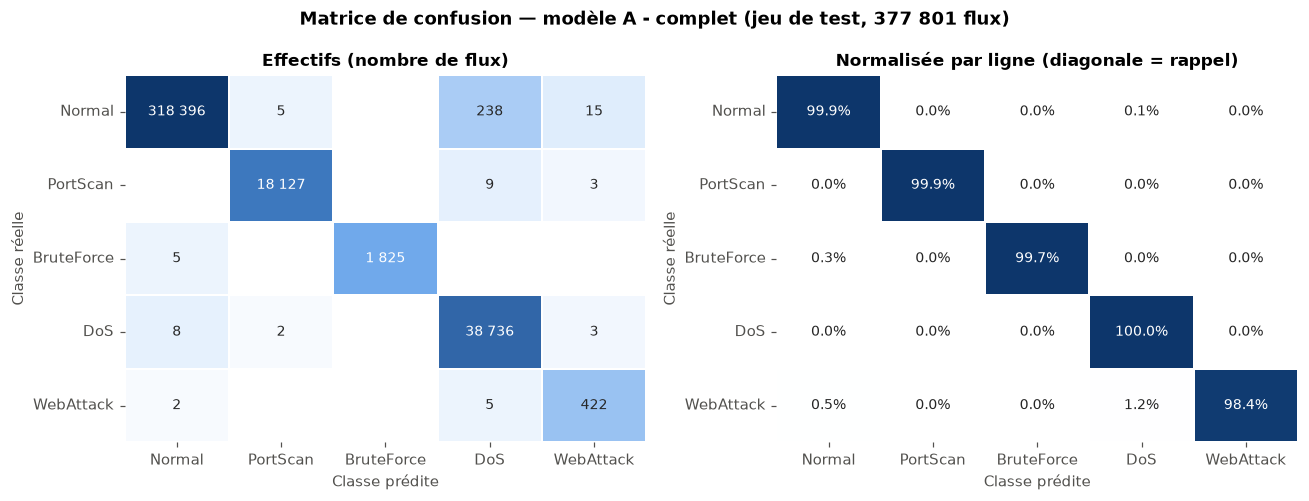

In [11]:
# --- FONCTION D'ÉVALUATION : métriques + matrice de confusion ----------------------
def evaluer(nom, m, fichier_png):
    y_pred = m["pipeline"].predict(m["X"].loc[idx_test])
    m["y_pred"] = y_pred

    # Métriques par classe ET moyennées
    print(f"=== Modèle {nom} — rapport de classification sur le test ===")
    print(classification_report(y_test, y_pred, labels=CLASSES, digits=4))

    # Matrice de confusion : lignes = classe réelle, colonnes = classe prédite.
    # À gauche les effectifs ; à droite chaque ligne est ramenée à 100 % : la diagonale
    # de droite est donc le RAPPEL de chaque classe (lisible malgré le déséquilibre).
    mc = confusion_matrix(y_test, y_pred, labels=CLASSES)
    mc_pct = mc / mc.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    sns.heatmap(mc, annot=np.vectorize(fmt)(mc), fmt="", cmap=CMAP_BLEU, cbar=False, ax=axes[0],
                norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=mc.max()), mask=(mc == 0),
                xticklabels=CLASSES, yticklabels=CLASSES, linewidths=1, linecolor="white",
                annot_kws={"fontsize": 9})
    axes[0].set_title("Effectifs (nombre de flux)")
    sns.heatmap(mc_pct, annot=True, fmt=".1%", cmap=CMAP_BLEU, cbar=False, ax=axes[1], vmin=0, vmax=1,
                xticklabels=CLASSES, yticklabels=CLASSES, linewidths=1, linecolor="white",
                annot_kws={"fontsize": 9})
    axes[1].set_title("Normalisée par ligne (diagonale = rappel)")
    for ax in axes:
        ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe réelle")
        ax.tick_params(axis="x", rotation=0); ax.tick_params(axis="y", rotation=0)
    fig.suptitle(f"Matrice de confusion — modèle {nom} (jeu de test, {fmt(len(y_test))} flux)",
                 fontweight="bold", fontsize=12)
    fig.tight_layout()
    fig.savefig(DOSSIER_FIGURES / fichier_png)
    plt.show()


evaluer("A - complet", MODELES["A - complet"], "03_matrice_confusion_complet.png")

=== Modèle B - compatible Zeek — rapport de classification sur le test ===


              precision    recall  f1-score   support

      Normal     0.9994    0.8980    0.9460    318654
    PortScan     0.4049    0.9964    0.5758     18139
  BruteForce     0.9322    1.0000    0.9649      1830
         DoS     0.9808    0.9957    0.9882     38749
   WebAttack     0.0762    0.9837    0.1414       429

    accuracy                         0.9133    377801
   macro avg     0.6787    0.9748    0.7233    377801
weighted avg     0.9676    0.9133    0.9317    377801



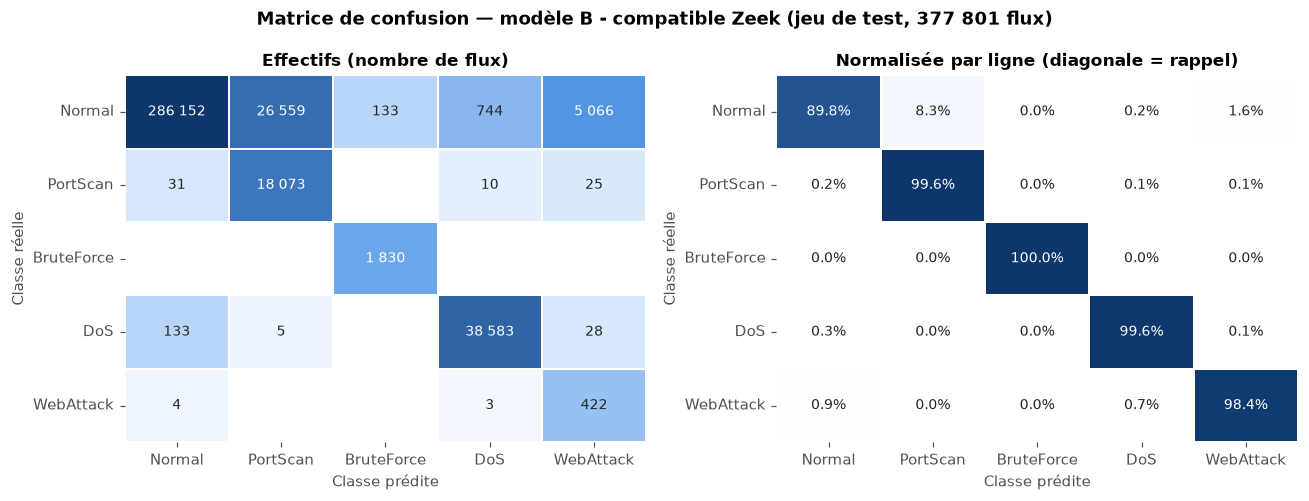

In [12]:
# --- ÉVALUATION DU MODÈLE B (celui de l'étape 7) ---------------------------------------
evaluer("B - compatible Zeek", MODELES["B - compatible Zeek"], "04_matrice_confusion_zeek.png")

### 4.1 Lecture des résultats

*(Chiffres de l'exécution de référence : dataset complet, `RANDOM_STATE = 42`. Ils sont reproductibles à l'identique.)*

**Modèle A (complet) — la référence « académique ».** Accuracy 99,92 %, F1 macro 99,24 %. Toutes les classes dépassent 99,7 % de rappel sauf WebAttack (98,4 % de rappel, 95,3 % de précision), la plus rare (429 flux de test). Les rares erreurs sont des flux Normal pris pour du DoS (238 sur 318 654). La validation croisée (F1 macro 0,9961 ± 0,0010) confirme que ce résultat est stable. **Mais ce score est à nuancer** : il bénéficie d'indices propres au banc d'essai du CIC (bourrage Ethernet, `Init_Win_bytes`, voir 4.2) qui n'existeront pas sur mon réseau.

**Modèle B (compatible Zeek) — le modèle réellement déployable.** Avec seulement 13 features et sans le raccourci du bourrage :
- **Le rappel reste excellent sur toutes les attaques** : PortScan 99,6 %, BruteForce 100 %, DoS 99,6 %, WebAttack 98,4 % → **99,7 % des flux d'attaque lèvent une alerte**. Pour un SOC c'est la priorité : une attaque manquée coûte plus cher qu'une fausse alerte.
- **BruteForce (précision 93,2 %) et DoS (98,1 %) sont bien caractérisés** par des statistiques de flux : sessions SSH/FTP courtes et répétitives à petits paquets ; flux HTTP très longs ou très volumineux vers un seul service.
- **La précision chute sur deux classes**, et la matrice de confusion montre exactement pourquoi :
  - **PortScan : précision 40,5 %** — 26 559 flux Normal sont annoncés PortScan. Une sonde de scan, c'est « 1 paquet aller, 1 paquet retour, 0 octet ». Or CICFlowMeter coupe les connexions au premier FIN et produit des milliers de *fragments* BENIGN ayant exactement cette forme. **Flux par flux, les deux sont identiques** : aucun algorithme ne peut les séparer avec ces features. Ce qui trahit un scan, ce n'est pas *un* flux mais *le nombre de ports différents touchés par une même source en quelques secondes* — information absente des CSV (ni IP, ni horodatage).
  - **WebAttack : précision 7,6 %** — 5 066 flux Normal annoncés WebAttack pour 422 vrais. Un XSS ou une injection SQL ne diffère d'une requête HTTP légitime que par son **contenu** (couche 7), invisible dans des compteurs de paquets et d'octets. C'est le domaine des **signatures Suricata** (règles HTTP), pas d'un modèle de flux.
- Au total, **10,2 % du trafic normal déclenche une fausse alerte** sur ce jeu de test. La validation croisée (F1 macro 0,849 ± 0,0003, très stable) est plus flatteuse que le test (0,723) uniquement parce qu'elle est calculée sur le train *rééquilibré* : avec moins de flux Normal, il y a mécaniquement moins de faux positifs. C'est l'illustration concrète de l'intérêt d'avoir gardé la distribution réelle dans le test.

**Ce que j'en conclus pour l'architecture du mini-SOC.**
1. Le module ML est un **détecteur complémentaire à fort rappel** : il signale des comportements (scan, brute force, DoS) *sans signature*, là où Suricata exige une règle. Wazuh corrèle les deux : une alerte ML confirmée par Suricata est prioritaire ; une alerte ML isolée « PortScan » sur un seul flux est de faible priorité.
2. **Piste d'amélioration n°1 (étape 7)** : agréger les alertes par IP source et par fenêtre de temps à partir de `conn.log` (ex. « plus de 20 ports distincts en 10 s »). Zeek fournit IP et horodatage, contrairement aux CSV de CICIDS2017 : cela éliminerait l'essentiel des faux positifs PortScan.
3. Les fragments de connexion à l'origine des faux positifs PortScan sont un artefact de CICFlowMeter que **Zeek ne produit pas** : le taux de fausses alertes réel devrait être inférieur à 10 % sur mon trafic — hypothèse à vérifier à l'étape 7.

### 4.2 Importance des features : ce que le modèle « regarde »

L'importance (*Gini importance*) mesure combien chaque feature contribue, en moyenne sur les 100 arbres, à séparer les classes. La somme vaut 1.
**Précautions de lecture** : (1) quand des features sont corrélées (ex. octets totaux / octets aller), l'importance se **partage** entre elles ; (2) cet indicateur dit *qu'une* feature est utile, pas *dans quel sens* — c'est l'arbre explicatif (4.3) qui montre les seuils.

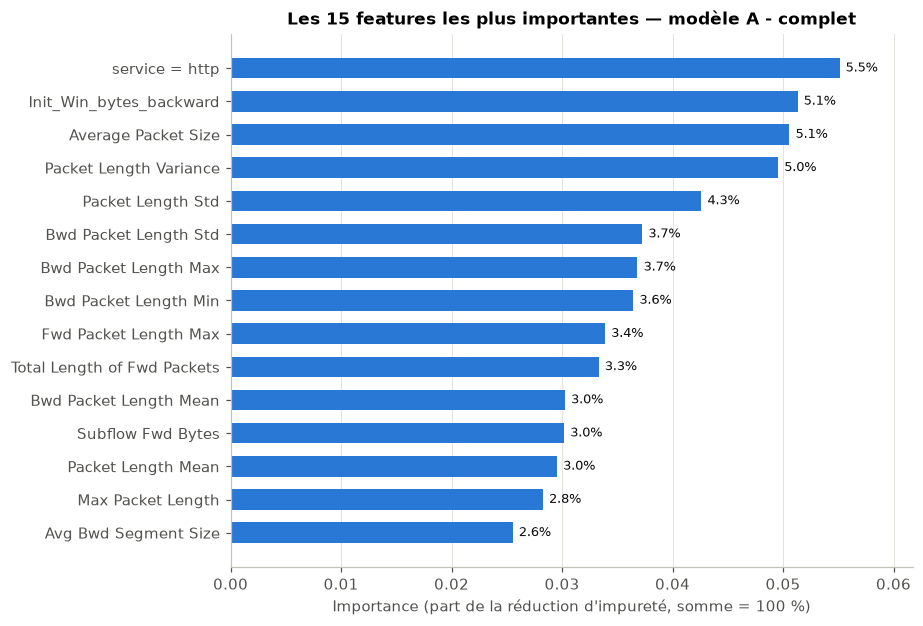

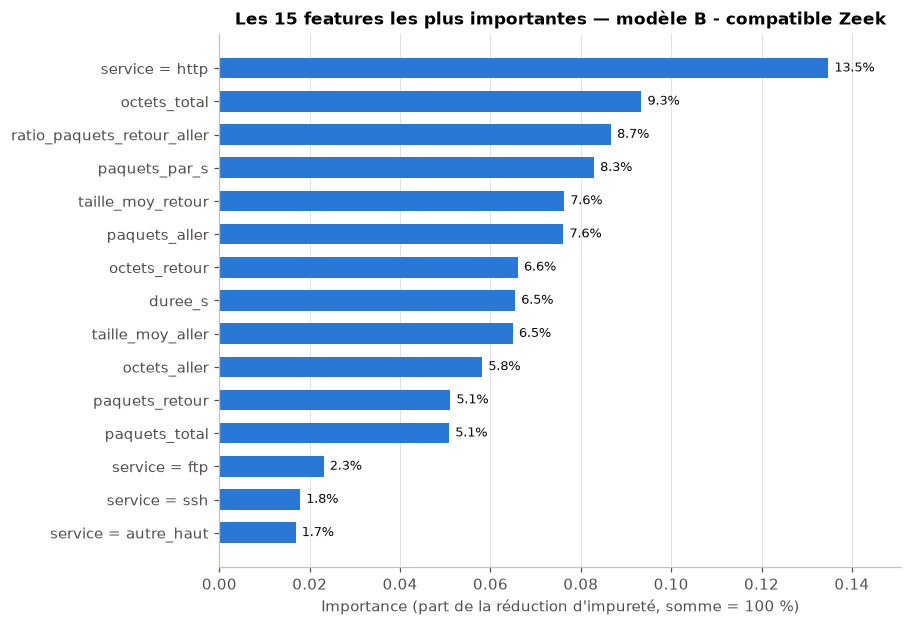

In [13]:
# --- IMPORTANCE DES FEATURES (FIGURES 5 ET 6) -----------------------------------------
def tracer_importances(nom, m, fichier_png, top=15):
    pipeline = m["pipeline"]
    noms = pipeline.named_steps["pretraitement"].get_feature_names_out()
    # "num__duree_s" -> "duree_s" ; "cat__service_http" -> "service = http"
    noms = [n.replace("num__", "").replace("cat__service_", "service = ") for n in noms]
    importances = pd.Series(pipeline.named_steps["foret"].feature_importances_, index=noms)
    m["importances"] = importances.sort_values(ascending=False)
    top_imp = m["importances"].head(top)[::-1]

    fig, ax = plt.subplots(figsize=(8, 0.34 * len(top_imp) + 1.2))
    ax.barh(top_imp.index, top_imp.values, height=0.62, color="#2a78d6")
    for i, v in enumerate(top_imp.values):
        ax.text(v + top_imp.max() * 0.01, i, f"{v:.1%}", va="center", fontsize=8.5, color="#0b0b0b")
    ax.set_xlim(0, top_imp.max() * 1.12)
    ax.set_xlabel("Importance (part de la réduction d'impureté, somme = 100 %)")
    ax.set_title(f"Les {len(top_imp)} features les plus importantes — modèle {nom}")
    ax.grid(axis="x", linewidth=0.6); ax.set_axisbelow(True)
    fig.savefig(DOSSIER_FIGURES / fichier_png)
    plt.show()


tracer_importances("A - complet", MODELES["A - complet"], "05_importance_features_complet.png")
tracer_importances("B - compatible Zeek", MODELES["B - compatible Zeek"], "06_importance_features_zeek.png")

**Lecture — modèle A.** L'importance est très répartie (aucune feature au-dessus de 6 %) : ce sont surtout les **statistiques de taille de paquets** (moyenne, variance, max, dans le sens retour notamment) qui séparent les classes, ce qui est cohérent : un scan n'a pas de données, un DoS HTTP provoque de grosses réponses, un brute force échange de petits paquets. Deux features appellent un regard critique : **`Init_Win_bytes_backward`** (2ᵉ) est la fenêtre TCP initiale du serveur — elle dépend du système d'exploitation des machines *du banc d'essai*, pas de l'attaque : c'est un raccourci propre au dataset ; **`service = http`** (1ʳᵉ) reflète le fait que, dans CICIDS2017, *tous* les DoS et toutes les attaques web visent le port 80.

**Lecture — modèle B.** Les 12 features numériques ont toutes un poids comparable (5 à 9 %) : le modèle combine **volume** (`octets_total`), **asymétrie** (`ratio_paquets_retour_aller` : le serveur répond-il ?), **cadence** (`paquets_par_s`, `duree_s`) et **taille moyenne des paquets**. `service = http` arrive en tête (13,5 %) pour la même raison que ci-dessus : savoir qu'un flux vise HTTP restreint immédiatement les classes possibles à Normal / DoS / WebAttack. `service = ftp` et `service = ssh` jouent le même rôle pour BruteForce.
**Limite à assumer devant le jury** : le modèle a appris que « DoS = HTTP » et « BruteForce = SSH/FTP » parce que le dataset ne contient que ces cas. Un DoS contre un autre service (ex. SYN flood sur le port 443) ou un brute force RDP pourraient être moins bien reconnus. Cela tombe bien pour mes scénarios (hydra sur SSH, HTTP flood), mais ce n'est pas une propriété générale.

### 4.3 Un arbre explicatif de profondeur 3 (support pour la soutenance)

Une forêt de 100 arbres profonds ne se dessine pas. Pour **montrer le principe** au jury, j'entraîne un *unique* arbre de décision limité à 3 niveaux, sur les features du modèle B **non normalisées** (les seuils s'expriment ainsi en vraies unités : secondes, octets, paquets). Ce n'est **pas** le modèle déployé : c'est une illustration de la logique que la forêt affine.

Arbre de profondeur 3 seul : rappel macro = 0.884, F1 macro = 0.521 sur le test

|--- service=http <= 0.5000
|   |--- octets_total <= 3.5000
|   |   |--- paquets_aller <= 1.5000
|   |   |   |--- class: PortScan
|   |   |--- paquets_aller >  1.5000
|   |   |   |--- class: Normal
|   |--- octets_total >  3.5000
|   |   |--- ratio_paquets_retour_aller <= 1.3458
|   |   |   |--- class: Normal
|   |   |--- ratio_paquets_retour_aller >  1.3458
|   |   |   |--- class: BruteForce
|--- service=http >  0.5000
|   |--- taille_moy_retour <= 880.4583
|   |   |--- ratio_paquets_retour_aller <= 0.3229
|   |   |   |--- class: DoS
|   |   |--- ratio_paquets_retour_aller >  0.3229
|   |   |   |--- class: WebAttack
|   |--- taille_moy_retour >  880.4583
|   |   |--- paquets_retour <= 9.5000
|   |   |   |--- class: DoS
|   |   |--- paquets_retour >  9.5000
|   |   |   |--- class: WebAttack



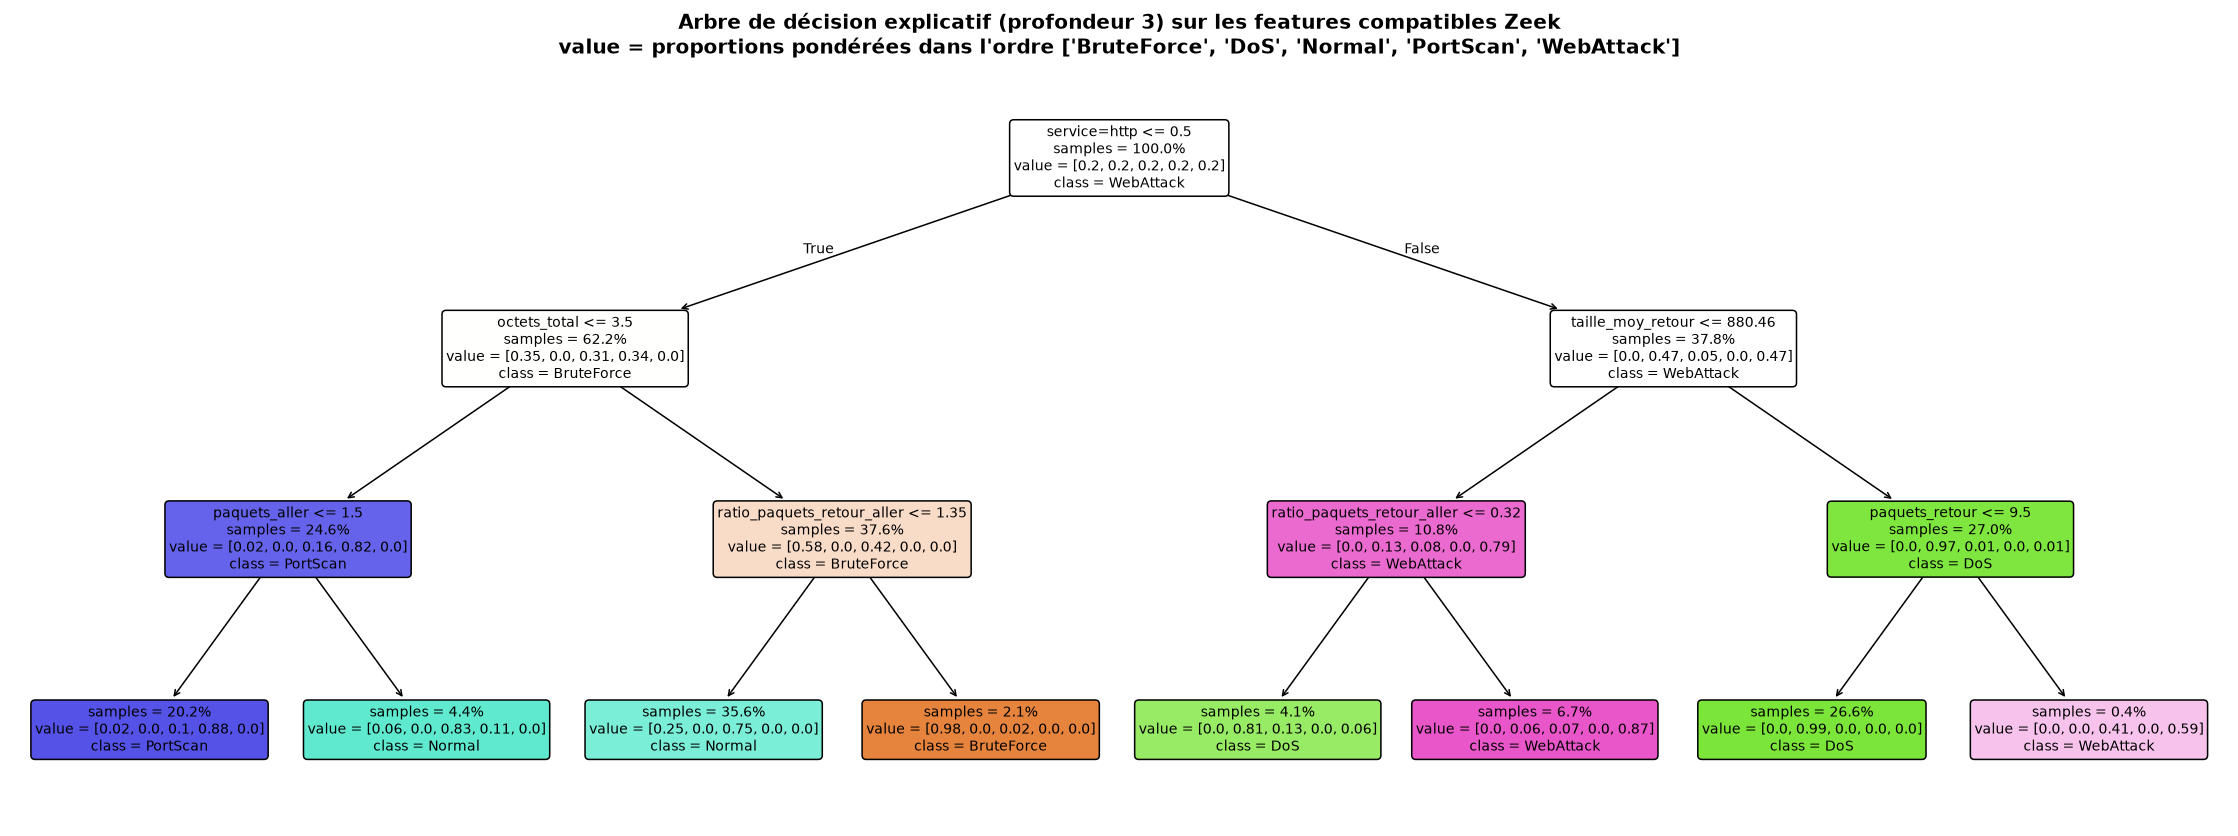

In [14]:
# --- ARBRE DE DÉCISION EXPLICATIF (FIGURE 7) --------------------------------------------
# get_dummies = encodage one-hot simple ; pas de StandardScaler pour garder des seuils lisibles.
X_arbre = pd.get_dummies(X_zeek, columns=["service"], prefix="service", prefix_sep="=", dtype=int)
arbre = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=RANDOM_STATE)
arbre.fit(X_arbre.loc[idx_train_eq], y_train)

p, r, f1_arbre, _ = precision_recall_fscore_support(y_test, arbre.predict(X_arbre.loc[idx_test]),
                                                    average="macro", zero_division=0)
print(f"Arbre de profondeur 3 seul : rappel macro = {r:.3f}, F1 macro = {f1_arbre:.3f} sur le test\n")
print(export_text(arbre, feature_names=list(X_arbre.columns), decimals=4))

fig, ax = plt.subplots(figsize=(26, 9))
plot_tree(arbre, feature_names=list(X_arbre.columns), class_names=list(arbre.classes_), filled=True,
          rounded=True, impurity=False, proportion=True, fontsize=9, ax=ax, precision=2)
ax.set_title("Arbre de décision explicatif (profondeur 3) sur les features compatibles Zeek\n"
             f"value = proportions pondérées dans l'ordre {list(arbre.classes_)}", fontsize=13)
fig.savefig(DOSSIER_FIGURES / "07_arbre_explicatif.png")
plt.show()

## 5. Sorties exploitables pour le rapport

### 5.1 Tableau récapitulatif des métriques (à copier tel quel)

In [15]:
# --- TABLEAU RÉCAPITULATIF : métriques par classe et moyennées, pour A et B ---------------
def tableau_metriques(y_vrai, y_pred):
    p, r, f1, support = precision_recall_fscore_support(y_vrai, y_pred, labels=CLASSES, zero_division=0)
    t = pd.DataFrame({"Précision": p, "Rappel": r, "F1-score": f1}, index=CLASSES)
    for nom_moy, moy in [("Moyenne macro", "macro"), ("Moyenne pondérée", "weighted")]:
        pm, rm, fm, _ = precision_recall_fscore_support(y_vrai, y_pred, average=moy, zero_division=0)
        t.loc[nom_moy] = [pm, rm, fm]
    t.loc["Accuracy globale"] = [np.nan, np.nan, accuracy_score(y_vrai, y_pred)]
    return t, support


tab_a, support = tableau_metriques(y_test, MODELES["A - complet"]["y_pred"])
tab_b, _ = tableau_metriques(y_test, MODELES["B - compatible Zeek"]["y_pred"])
recap = pd.concat({"Modèle A (complet)": tab_a, "Modèle B (compatible Zeek)": tab_b}, axis=1)
recap.insert(0, "Flux de test", list(support) + [support.sum()] * 3)

# Export : CSV "français" (; et virgule décimale) qui s'ouvre directement dans Excel/Word
recap.round(4).to_csv("sorties/tableau_metriques.csv", sep=";", decimal=",", encoding="utf-8-sig")
display(recap.style.format("{:.4f}", na_rep="—", subset=recap.columns[1:]).format(fmt, subset=["Flux de test"]))
# Vue "SOC" binaire : peu importe le TYPE d'attaque annoncé, l'attaque a-t-elle levé une alerte ?
for nom, m in MODELES.items():
    alerte = m["y_pred"] != "Normal"
    m["detection"] = alerte[(y_test != "Normal").values].mean()
    m["fausses_alertes"] = alerte[(y_test == "Normal").values].mean()
    print(f"Modèle {nom:20s}: taux de détection global = {m['detection']:.2%}   |   "
          f"taux de fausses alertes sur le trafic normal = {m['fausses_alertes']:.2%}")
print("Tableau enregistré : sorties/tableau_metriques.csv  (le tableau ci-dessus se copie-colle aussi dans Word)")

Modèle A - complet         : taux de détection global = 99.97%   |   taux de fausses alertes sur le trafic normal = 0.08%
Modèle B - compatible Zeek : taux de détection global = 99.72%   |   taux de fausses alertes sur le trafic normal = 10.20%
Tableau enregistré : sorties/tableau_metriques.csv  (le tableau ci-dessus se copie-colle aussi dans Word)


In [16]:
# --- SAUVEGARDE DES MODÈLES (joblib) ---------------------------------------------------------
# Chaque fichier contient le Pipeline COMPLET (normalisation + encodage + forêt) :
# à l'étape 7 on lui donnera des valeurs brutes, sans refaire le prétraitement à la main.
# compress=3 : fichier ~5x plus petit pour un temps de chargement à peine plus long.
joblib.dump(MODELES["B - compatible Zeek"]["pipeline"], DOSSIER_MODELES / "modele_rf_zeek.joblib", compress=3)
joblib.dump(MODELES["A - complet"]["pipeline"], DOSSIER_MODELES / "modele_rf_complet.joblib", compress=3)
for f in sorted(DOSSIER_MODELES.glob("*.joblib")):
    print(f"{f}  ({f.stat().st_size / 1e6:.1f} Mo)")
print("\nFigures enregistrées :")
for f in sorted(DOSSIER_FIGURES.glob("*.png")):
    print("  ", f)

sorties\modeles\modele_rf_complet.joblib  (2.5 Mo)
sorties\modeles\modele_rf_zeek.joblib  (3.0 Mo)

Figures enregistrées :
   sorties\figures\01_distribution_classes.png
   sorties\figures\02_reequilibrage_train.png
   sorties\figures\03_matrice_confusion_complet.png
   sorties\figures\04_matrice_confusion_zeek.png
   sorties\figures\05_importance_features_complet.png
   sorties\figures\06_importance_features_zeek.png
   sorties\figures\07_arbre_explicatif.png


### 5.2 La fonction `predict(flux)`

Elle est définie dans **`predire.py`** (pour être importable à l'étape 7 sans ouvrir le notebook). Elle charge `modele_rf_zeek.joblib`, prend les **6 grandeurs de base** d'un flux, recalcule les 13 features avec `construire_features()` et renvoie la classe.
`predict_detail(flux)` renvoie en plus la **confiance** (part des arbres ayant voté pour la classe) — utile pour ne remonter vers Wazuh que les alertes au-dessus d'un seuil.

In [17]:
# --- DÉMONSTRATION DE predict() ------------------------------------------------------------------
# Trois flux "écrits à la main" avec des valeurs typiques, puis vérification sur de vrais flux du test.
from predire import predict, predict_detail

exemples = {
    "Sonde nmap sur port fermé": dict(duree_s=0.00005, paquets_aller=1, paquets_retour=1,
                                      octets_aller=0, octets_retour=0, port_dest=3389),
    "Tentative de login SSH (hydra)": dict(duree_s=2.4, paquets_aller=14, paquets_retour=16,
                                           octets_aller=1128, octets_retour=2009, port_dest=22),
    "Navigation HTTPS ordinaire": dict(duree_s=1.8, paquets_aller=12, paquets_retour=14,
                                       octets_aller=900, octets_retour=6500, port_dest=443),
}
for description, flux in exemples.items():
    print(f"{description:32s} -> {predict(flux)}")

print("\nDétail (probabilités) sur 2 vrais flux de test par classe :")
echantillon_test = y_test.groupby(y_test).head(2).index
detail = predict_detail(base_depuis_cicids(df.loc[echantillon_test]))
detail.insert(0, "classe_reelle", y_test.loc[echantillon_test])
display(detail)

Sonde nmap sur port fermé        -> PortScan
Tentative de login SSH (hydra)   -> BruteForce
Navigation HTTPS ordinaire       -> Normal

Détail (probabilités) sur 2 vrais flux de test par classe :


,classe_reelle,classe_predite,confiance,p_BruteForce,p_DoS,p_Normal,p_PortScan,p_WebAttack
199471,Normal,Normal,1.000,0.000,0.000,1.000,0.000,0.000
771797,Normal,Normal,1.000,0.000,0.000,1.000,0.000,0.000
1153975,DoS,DoS,0.999,0.000,0.999,0.000,0.000,0.001
1835100,PortScan,PortScan,0.912,0.002,0.000,0.085,0.912,0.001
1786118,PortScan,PortScan,0.983,0.004,0.000,0.012,0.983,0.001
1014242,DoS,DoS,1.000,0.000,1.000,0.000,0.000,0.000
528699,BruteForce,BruteForce,1.000,1.000,0.000,0.000,0.000,0.000
538085,BruteForce,BruteForce,1.000,1.000,0.000,0.000,0.000,0.000
1571238,WebAttack,WebAttack,1.000,0.000,0.000,0.000,0.000,1.000
1562681,WebAttack,WebAttack,0.981,0.000,0.000,0.018,0.000,0.981


## 6. Lien avec mon trafic réel (étape 7) : de Zeek `conn.log` au modèle

### 6.1 Principe
1. Installer **Zeek** sur une sonde qui voit le trafic inter-VLAN (port miroir / interface de capture de pfSense, ou rejouer un `.pcap` : `zeek -r capture.pcap`).
2. Zeek produit **`conn.log`** : une ligne par connexion, l'équivalent d'un « flux » CICFlowMeter.
3. `zeek_vers_modele.py` lit ce fichier, le convertit avec `base_depuis_zeek()` + `construire_features()` (mêmes formules qu'à l'entraînement) et appelle le modèle B.
4. Comme je connais l'IP de Kali et l'heure de chaque attaque, je peux **étiqueter** ces flux et calculer de vraies métriques « conditions réelles ».

### 6.2 Correspondance des features

| Grandeur de base | Colonne CICIDS2017 (CICFlowMeter) | Champ Zeek `conn.log` | Remarque |
|---|---|---|---|
| `duree_s` | `Flow Duration` (µs) ÷ 10⁶ | `duration` (s) | `-` dans Zeek si un seul paquet → 0 |
| `paquets_aller` | `Total Fwd Packets` | `orig_pkts` | « aller » = de l'initiateur vers le serveur |
| `paquets_retour` | `Total Backward Packets` | `resp_pkts` | |
| `octets_aller` | `Total Length of Fwd Packets` | `orig_bytes` | octets de **charge utile** des deux côtés (pas `orig_ip_bytes`, qui inclut les en-têtes) |
| `octets_retour` | `Total Length of Bwd Packets` | `resp_bytes` | |
| `port_dest` → `service` | `Destination Port` | `id.resp_p` | catégorisé par `categoriser_service()` |

| Feature dérivée (recalculée des deux côtés par la même fonction) | Formule | Équivalent d'origine dans CICIDS2017 |
|---|---|---|
| `paquets_total`, `octets_total` | somme aller + retour | — |
| `octets_par_s`, `paquets_par_s` | total ÷ durée (0 si durée nulle) | `Flow Bytes/s`, `Flow Packets/s` |
| `taille_moy_aller`, `taille_moy_retour` | octets ÷ paquets | `Fwd/Bwd Packet Length Mean` |
| `ratio_paquets_retour_aller` | paquets retour ÷ paquets aller | `Down/Up Ratio` |

**Features de CICIDS2017 sans équivalent dans `conn.log`** (donc absentes du modèle B) : temps inter-arrivées (`IAT`), min/max/écart-type des tailles de paquets, fenêtres TCP initiales (`Init_Win_bytes`), temps actif/inactif. Zeek fournit en revanche `conn_state` et `history` (S0, REJ, SF…), très parlants pour les scans, mais **inutilisables ici** car les flags correspondants sont bogués dans CICIDS2017 : je les affiche comme *contexte* à côté de la prédiction.

In [18]:
# --- EXEMPLE : LIRE UN conn.log ZEEK ET LE PASSER AU MODÈLE -----------------------------------------
# data/exemple_conn.log est un PETIT FICHIER FABRIQUÉ À LA MAIN au format Zeek (TSV) : 4 sondes de scan,
# 3 sessions SSH courtes, 3 connexions normales, 1 ICMP. Il sert à tester la CHAÎNE DE LECTURE,
# pas à mesurer une performance : à l'étape 7, on le remplace par le vrai conn.log de mon réseau.
from zeek_vers_modele import classer_conn_log, lire_conn_log

print(inspect.getsource(lire_conn_log))
resultat_zeek = classer_conn_log("data/exemple_conn.log")
display(resultat_zeek.drop(columns=["ts"]))

def lire_conn_log(chemin):
    """Lit un conn.log Zeek et renvoie un DataFrame (une ligne = une connexion).

    Format TSV de Zeek : des lignes d'en-tête commençant par '#'. La ligne
    '#fields' donne le nom des colonnes ; les valeurs absentes sont notées '-'.
    """
    with open(chemin, encoding="utf-8") as f:
        premiere = f.readline()
    if premiere.lstrip().startswith("{"):                       # --- format JSON (1 objet / ligne)
        with open(chemin, encoding="utf-8") as f:
            return pd.DataFrame([json.loads(ligne) for ligne in f if ligne.strip()])

    colonnes = None                                             # --- format TSV (par défaut)
    with open(chemin, encoding="utf-8") as f:
        for ligne in f:
            if ligne.startswith("#fields"):
                colonnes = ligne.rstrip("\n").split("\t")[1:]
                break
    if colonnes is None:
        raise ValueError("Ligne '#fields' introuvable : ce fichier n'est pas un conn.log Zeek.")


,id.orig_h,id.resp_h,id.resp_p,proto,service,conn_state,duree_s,paquets_aller,paquets_retour,octets_aller,octets_retour,classe_predite,confiance,p_BruteForce,p_DoS,p_Normal,p_PortScan,p_WebAttack
0,10.10.99.50,10.10.30.10,3389,tcp,NaN,REJ,0.000046,1,1,0.0,0.0,PortScan,0.914,0.002,0.000,0.083,0.914,0.001
1,10.10.99.50,10.10.30.10,5900,tcp,NaN,REJ,0.000051,1,1,0.0,0.0,PortScan,0.912,0.002,0.000,0.085,0.912,0.001
2,10.10.99.50,10.10.30.10,8443,tcp,NaN,REJ,0.000039,1,1,0.0,0.0,PortScan,0.914,0.002,0.000,0.084,0.914,0.001
3,10.10.99.50,10.10.30.10,135,tcp,NaN,S0,0.000000,1,0,0.0,0.0,Normal,0.496,0.078,0.029,0.496,0.396,0.000
4,10.10.99.50,10.10.30.10,22,tcp,ssh,SF,2.431000,14,16,1128.0,2009.0,BruteForce,0.883,0.883,0.000,0.117,0.000,0.000
5,10.10.99.50,10.10.30.10,22,tcp,ssh,SF,2.517000,14,16,1128.0,2009.0,BruteForce,0.884,0.884,0.000,0.116,0.000,0.000
6,10.10.99.50,10.10.30.10,22,tcp,ssh,SF,2.389000,15,16,1144.0,2009.0,BruteForce,0.826,0.826,0.000,0.174,0.000,0.000
7,10.10.10.21,10.10.30.53,53,udp,dns,SF,0.021000,1,1,43.0,112.0,Normal,1.000,0.000,0.000,1.000,0.000,0.000
8,10.10.10.21,142.250.75.4,443,tcp,ssl,SF,1.842000,12,14,912.0,6480.0,Normal,1.000,0.000,0.000,1.000,0.000,0.000
9,10.10.10.21,10.10.30.10,80,tcp,http,SF,0.318000,6,7,402.0,5120.0,Normal,1.000,0.000,0.000,1.000,0.000,0.000


### 6.3 Mesurer la performance en conditions réelles (à faire à l'étape 7)

```python
from sklearn.metrics import classification_report
from zeek_vers_modele import classer_conn_log

res = classer_conn_log("conn.log")                       # prédictions du modèle B
IP_KALI = "10.10.99.50"                                  # à adapter

# Vérité terrain : je connais l'attaquant et l'heure (timestamp Unix) de chaque scénario
res["classe_reelle"] = "Normal"
scenarios = [("PortScan",   1789812000, 1789812300),     # nmap   : début, fin
             ("BruteForce", 1789812600, 1789813200),     # hydra
             ("DoS",        1789813500, 1789813800)]     # flood
for classe, debut, fin in scenarios:
    masque = (res["id.orig_h"] == IP_KALI) & res["ts"].between(debut, fin)
    res.loc[masque, "classe_reelle"] = classe

print(classification_report(res["classe_reelle"], res["classe_predite"], digits=3))
```

### 6.4 Écarts attendus entre CICFlowMeter et Zeek (à citer dans les limites)
- **Découpage des flux** : CICFlowMeter coupe un flux après 120 s ou au premier FIN ; Zeek garde la connexion entière. Un DoS lent (slowloris) apparaîtra donc comme des flux plus longs dans Zeek.
- **Octets des paquets vides** : CICFlowMeter compte le bourrage Ethernet (2 à 6 octets) comme charge utile, Zeek non. Écart **déjà neutralisé** dans `construire_features()` (section 2.1) ; il reste une légère surestimation des octets dans CICIDS2017 pour les flux contenant beaucoup d'ACK purs.
- **Fragments de connexions** : en coupant les flux au premier FIN, CICFlowMeter crée de nombreux mini-flux « 1 paquet aller, 1 paquet retour, 0 octet » étiquetés BENIGN, identiques à une sonde de scan. Zeek ne produit pas ces fragments : le taux de fausses alertes PortScan devrait donc être **plus faible sur mon trafic** que sur le test CICIDS2017 — à vérifier à l'étape 7.
- **Ports filtrés par pfSense** : un pare-feu qui *jette* les paquets (pas de RST) donne dans Zeek des flux `S0` « 1 paquet aller, 0 retour ». CICIDS2017 en contient très peu côté PortScan (les cibles répondaient par RST) : dans l'exemple ci-dessus, ce cas est classé `Normal` avec une confiance faible (≈ 0,50 contre 0,40 pour PortScan). À l'étape 7, je dois donc m'attendre à un meilleur rappel sur les scans *intra-VLAN* (RST) que sur les scans *à travers pfSense* (S0), et regarder la colonne `conn_state` à côté de la prédiction.
- **Sens du flux** : identique en principe (le premier paquet définit l'initiateur), sauf si la capture démarre au milieu d'une connexion.
- **Réseau différent** : débits, latences et services de mon labo virtualisé diffèrent du banc d'essai du CIC. Une baisse de performance est **attendue** ; la quantifier *est* le résultat de l'étape 7. Si elle est forte, la suite logique est de ré-entraîner le modèle en ajoutant une partie de mes propres flux étiquetés.

## 7. Synthèse pour le rapport

Le paragraphe ci-dessous est **généré à partir des métriques réellement obtenues** lors de cette exécution (il se met à jour si je relance le notebook). Il est aussi enregistré dans `sorties/synthese_rapport.txt`.

In [19]:
# --- PARAGRAPHE DE SYNTHÈSE, REMPLI AVEC LES VRAIES MÉTRIQUES ------------------------------------------
A, B = tab_a, tab_b
cv_a, cv_b = MODELES["A - complet"]["cv_f1"], MODELES["B - compatible Zeek"]["cv_f1"]
pc = lambda v: f"{100 * v:.1f} %".replace(".", ",")         # 0.9937 -> "99,4 %"

mB = MODELES["B - compatible Zeek"]
synthese = (
    f"Le module Machine Learning classe chaque flux réseau en cinq classes (Normal, PortScan, BruteForce, DoS, WebAttack) "
    f"alignées sur les scénarios d'attaque du projet. Il est entraîné sur CICIDS2017 (cinq journées), soit {fmt(len(df))} flux "
    f"après nettoyage explicite (NaN/Infinity, durées négatives, doublons). Le déséquilibre ({distribution['Normal'] / distribution.sum():.0%} "
    f"de trafic normal) est traité par sous-échantillonnage de la classe Normal dans le jeu d'entraînement et pondération des "
    f"classes ; le jeu de test (20 %, stratifié) conserve la distribution réelle. L'algorithme est un Random Forest (100 arbres), "
    f"retenu pour son interprétabilité et sa légèreté. Avec toutes les features du dataset (modèle A), il atteint {pc(A.loc['Accuracy globale', 'F1-score'])} "
    f"d'accuracy et un F1 macro de {pc(A.loc['Moyenne macro', 'F1-score'])} (validation croisée : {pc(cv_a.mean())}). Le modèle B, limité aux "
    f"13 caractéristiques recalculables depuis le conn.log de Zeek et corrigé d'un artefact du dataset (bourrage Ethernet), détecte "
    f"{pc(mB['detection'])} des attaques (rappel : PortScan {pc(B.loc['PortScan', 'Rappel'])}, BruteForce {pc(B.loc['BruteForce', 'Rappel'])}, "
    f"DoS {pc(B.loc['DoS', 'Rappel'])}, WebAttack {pc(B.loc['WebAttack', 'Rappel'])}) pour un F1 macro de {pc(B.loc['Moyenne macro', 'F1-score'])}, "
    f"au prix de {pc(mB['fausses_alertes'])} de fausses alertes sur le trafic normal : la précision chute pour PortScan "
    f"({pc(B.loc['PortScan', 'Précision'])}) et WebAttack ({pc(B.loc['WebAttack', 'Précision'])}), car une sonde isolée ou une requête HTTP "
    f"malveillante ressemblent, en statistiques de flux, à du trafic légitime. Limites : évaluation sur l'environnement du dataset "
    f"(la généralisation à mon réseau sera mesurée à l'étape 7), pas de vision du contenu applicatif ni de la couche 2 (ARP spoofing) : "
    f"le module complète Suricata et Wazuh sans les remplacer."
)
Path("sorties/synthese_rapport.txt").write_text(synthese, encoding="utf-8")
print(synthese)

Le module Machine Learning classe chaque flux réseau en cinq classes (Normal, PortScan, BruteForce, DoS, WebAttack) alignées sur les scénarios d'attaque du projet. Il est entraîné sur CICIDS2017 (cinq journées), soit 1 889 004 flux après nettoyage explicite (NaN/Infinity, durées négatives, doublons). Le déséquilibre (84% de trafic normal) est traité par sous-échantillonnage de la classe Normal dans le jeu d'entraînement et pondération des classes ; le jeu de test (20 %, stratifié) conserve la distribution réelle. L'algorithme est un Random Forest (100 arbres), retenu pour son interprétabilité et sa légèreté. Avec toutes les features du dataset (modèle A), il atteint 99,9 % d'accuracy et un F1 macro de 99,2 % (validation croisée : 99,6 %). Le modèle B, limité aux 13 caractéristiques recalculables depuis le conn.log de Zeek et corrigé d'un artefact du dataset (bourrage Ethernet), détecte 99,7 % des attaques (rappel : PortScan 99,6 %, BruteForce 100,0 %, DoS 99,6 %, WebAttack 98,4 %) pour